<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 3. Explorative Datenanalyse

In diesem Abschnitt wird die Datenbasis für das Pairs-Trading-Projekt systematisch untersucht. Ziel der explorativen Datenanalyse (EDA) ist es, ein Verständnis für die Struktur, Qualität und statistischen Eigenschaften der Kursdaten zu gewinnen, bevor darauf aufbauend Modelle für das maschinelle Lernen entwickelt werden.

Die analysierten Daten bestehen aus hochfrequenten Kurszeitreihen des S&P 500 mit einer zeitlichen Auflösung von einer Minute (Dateien: `sp500_1min_YYYY-MM-DD.csv`). Jede Zeile repräsentiert den Kurs eines bestimmten Wertpapiers zu einem gegebenen Zeitpunkt.

Das Vorgehen in diesem Kapitel gliedert sich in mehrere Schritte:

1. **Datenüberblick und Datenqualität**  
   Laden des Datensatzes, erste Kennzahlen (Anzahl Zeilen, Anzahl Ticker) und Prüfung auf fehlende Werte.
   Datensatz inspizieren, Datenlücken analyysieren und Datensatz säubern

3. **Untersuchung von Beziehungen zwischen Aktien**  
   Berechnung von Korrelationen zwischen Kursreihen und Darstellung stark korrelierter Aktienbeziehungen in Form eines Netzwerks.

2. **Fazit**
   


## 3.1. Theoretische Grundlage

Das Pairs Trading basiert auf der Annahme, dass sich die Kurse zweier stark miteinander verbundener Wertpapiere langfristig in einem stabilen Verhältnis bewegen.  
Wenn dieses Gleichgewicht vorübergehend gestört wird, eröffnet sich eine potenzielle Arbitragemöglichkeit: man geht in die unterbewertete Aktie **long** und in die überbewertete **short**, in Erwartung einer Rückkehr zum Mittelwert.

Damit diese Strategie fundiert umgesetzt werden kann, müssen drei zentrale Konzepte verstanden und überprüft werden.

### Korrelation

Die lineare Korrelation beschreibt, inwieweit sich zwei Zeitreihen gemeinsam bewegen.  
Sie wird durch den **Pearson-Korrelationskoeffizienten** $\rho_{X,Y}$ berechnet:

$$
\rho_{X,Y} = \frac{\mathrm{Cov}(X_t, Y_t)}{\sigma_X \cdot \sigma_Y}
$$

Ein Wert von $\rho_{X,Y} = 1$ bedeutet eine perfekte positive lineare Beziehung, während $\rho_{X,Y} = 0$ auf keinen linearen Zusammenhang hinweist.  
Im Rahmen des Pairs Trading deutet eine hohe Korrelation auf **ähnliches kurzfristiges Preisverhalten** hin – sie allein garantiert jedoch **keine langfristige Stabilität** der Beziehung.

### Cointegration

Zwei Preisreihen können stark korreliert sein, ohne eine langfristige Gleichgewichtsbeziehung zu besitzen.  
Die **Cointegration** erweitert das Konzept der Korrelation, indem sie prüft, ob eine lineare Kombination zweier nicht-stationärer Zeitreihen stationär ist.  
Formell gilt:

$$
Y_t = \alpha + \beta X_t + \varepsilon_t, \quad \varepsilon_t \sim I(0)
$$

Wenn der Fehlerterm $\varepsilon_t$ stationär ist, bedeutet dies, dass die beiden Reihen $X_t$ und $\ Y_t$ **gemeinsam einem langfristigen Gleichgewicht** folgen.  
Dies ist die theoretische Grundlage für die Berechnung des sogenannten **Spreads** im Pairs Trading.

### Stationarität

Der Spread $S_t = Y_t - \beta X_t$ beschreibt die Abweichung einer Aktie von der linearen Beziehung zur anderen.  
Damit eine Mean-Reversion-Strategie sinnvoll ist, muss der Spread stationär sein – das heißt, er schwankt um einen stabilen Mittelwert.

Um die Stärke der Abweichung zu messen, wird der Spread meist standardisiert:

$$
Z_t = \frac{S_t - \mu_S}{\sigma_S}
$$

Ein hoher Z-Score (z. B. > 2) deutet auf eine Überbewertung (Short-Signal), ein niedriger Z-Score (z. B. < −2) auf eine Unterbewertung (Long-Signal) hin.  
Die Analyse von Korrelation, Cointegration und Z-Score bildet daher die theoretische Basis, um **Paare mit stabiler, mean-revertierender Beziehung** zu identifizieren.

## 3.2. Datenqualität

### 3.2.1. Überblick
Bevor statistische Analysen oder Modellierungen durchgeführt werden, muss ein grundlegendes Verständnis des verwendeten Datensatzes geschaffen werden.  
In diesem Abschnitt werden Struktur, Umfang und Qualität der zugrunde liegenden Kursdaten untersucht.

Die verwendeten Daten bestehen aus hochfrequenten 1-Minuten-Preisen der im S&P 500 enthaltenen Aktien. Der rohe Datensatz umfasst Kurse vom **07. November 2025** bis zum **DATUM NOCH NICHT DEFINIERT** und enthält insgesamt mehrere millionen Zeilen.  
Jede Zeile repräsentiert den Preis eines bestimmten Wertpapiers zu einem bestimmten Zeitpunkt (`datetime`).

Zunächst werden grundlegende Kennzahlen wie die Anzahl der Zeilen und der enthaltenen Ticker (Symbole) ermittelt. Anschließend erfolgt eine Prüfung auf fehlende Werte, um Datenlücken oder Unstimmigkeiten im Datensatz zu identifizieren.

Diese Analyse dient als Grundlage für alle weiteren Schritte der explorativen Datenanalyse, da nur ein qualitativ hochwertiger Datensatz verlässliche Ergebnisse liefern kann.


In [46]:
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import networkx as nx
from pathlib import Path
from statsmodels.tsa.stattools import coint

# Stil für alle Diagramme
plt.style.use("seaborn-v0_8-whitegrid")

# Alle CSV-Dateien (mehrere Tage) laden
data_dir = Path("Daten")
files = sorted(data_dir.glob("sp500_1min_*.csv"))

dfs = []  # Liste für alle Tages-DataFrames

for file in files:
    df_day = pd.read_csv(file, parse_dates=["datetime"])
    df_day["date"] = df_day["datetime"].dt.date
    dfs.append(df_day)

# Alle Tage zu einem DataFrame zusammenführen
df = pd.concat(dfs, ignore_index=True)
df = df.sort_values("datetime").reset_index(drop=True)

# Erste Kennzahlen
print(f"Anzahl Zeilen gesamt: {len(df):,}")
print(f"Anzahl Ticker gesamt: {df['symbol'].nunique()}")
print(f"Anzahl Handelstage: {df['date'].nunique()}")

# Vorschau
df.head()


Anzahl Zeilen gesamt: 982,559
Anzahl Ticker gesamt: 504
Anzahl Handelstage: 5


,symbol,datetime,open,high,low,close,volume,date
0,MMM,2025-11-07 14:30:00,163.910004,163.929993,163.389999,163.820007,45015.0,2025-11-07
1,GRMN,2025-11-07 14:30:00,203.750000,203.750000,202.350006,203.175003,60789.0,2025-11-07
2,TRGP,2025-11-07 14:30:00,169.190002,171.070007,168.160004,170.470001,13935.0,2025-11-07
3,FI,2025-11-07 14:30:00,60.950001,61.740002,60.950001,61.509998,463772.0,2025-11-07
4,SRE,2025-11-07 14:30:00,93.070000,93.949997,92.889999,93.949997,43690.0,2025-11-07


### 3.2.2. Fehlende Werte
Ein wesentlicher Aspekt der Datenqualität ist das Vorhandensein fehlender Werte.  
Fehlende oder unvollständige Kursdaten können sowohl die Berechnung statistischer Kennzahlen als auch die Ergebnisse maschineller Lernverfahren erheblich beeinflussen.  
In diesem Schritt wird überprüft, in welchem Umfang solche Datenlücken existieren und wie sie sich über die Aktien verteilen.

Zunächst werden die Spalten des Datensatzes auf fehlende Werte (`NaN`) überprüft, um einen allgemeinen Überblick zu gewinnen. Anschließend wird die Anzahl der verfügbaren Datenpunkte je Aktie bestimmt, um potenziell unvollständige Zeitreihen zu identifizieren.

Diese Analysen ermöglichen es, die Datenqualität vor der Modellierung quantitativ zu bewerten und entscheiden zu können, ob bestimmte Symbole aufgrund von Datenlücken ausgeschlossen oder bearbeitet werden müssen.


Es gibt 369 Aktien mit mindestens einem fehlenden Wert.

Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):
symbol
NVR     1286
ERIE    1230
NDSN    1139
TPL     1115
AIZ     1004
CINF     916
GWW      820
GL       706
SNA      658
ALLE     637
AVY      636
UHS      630
L        627
IEX      600
PKG      594
dtype: int64


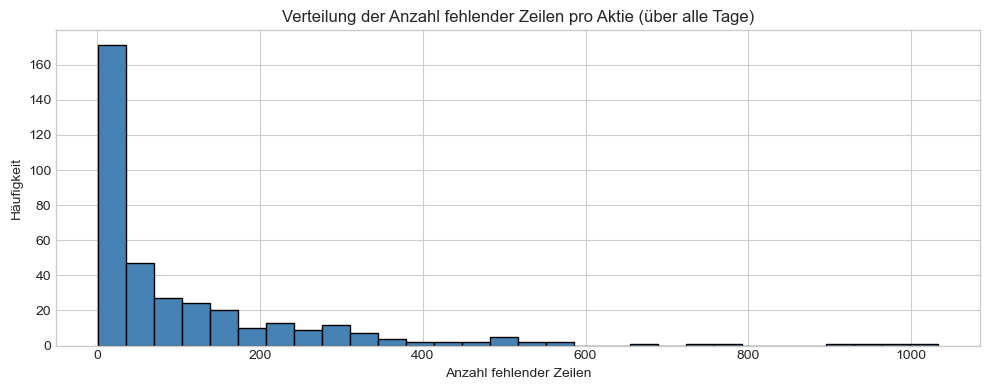

In [47]:
# Sicherstellen: datetime als Datetime, Hilfsspalten
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df = df.sort_values("datetime").reset_index(drop=True)
df["date"] = df["datetime"].dt.date
df["time"] = df["datetime"].dt.time

# Alle Zeilen mit >= 1 NaN in irgendeiner Spalte
is_missing_row = df.isna().any(axis=1)
missing_rows = df[is_missing_row].copy()

# Nach Ticker gruppieren und zählen (über ALLE Tage)
missing_by_symbol = (
    missing_rows.groupby("symbol").size().sort_values(ascending=False)
)

print(f"Es gibt {missing_by_symbol.size} Aktien mit mindestens einem fehlenden Wert.\n")
print("Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):")
print(missing_by_symbol.head(15))

# Histogramm: Verteilung fehlender Daten nach Aktie (über alle Tage)
plt.figure(figsize=(10,4))
missing_by_symbol.plot(kind="hist", bins=30, color="steelblue", edgecolor="black")
plt.title("Verteilung der Anzahl fehlender Zeilen pro Aktie (über alle Tage)")
plt.xlabel("Anzahl fehlender Zeilen")
plt.ylabel("Häufigkeit")
plt.tight_layout()
plt.show()

# Nach Zeitstempel gruppieren (mehrere Tage!) und zählen
missing_by_timestamp = missing_rows.groupby("datetime").size().rename("count")
missing_time_df = missing_by_timestamp.reset_index()


Die meisten Aktien haben nur sehr wenige fehlende Datenpunkte, einige wenige jedoch deutlich mehr.

Nachdem festgestellt wurde, welche Aktien unvollständige Zeitreihen besitzen, wird nun untersucht, **wann** diese Datenlücken im jeweiligen Tagesverlauf auftreten.  
Diese Analyse hilft zu erkennen, ob die fehlenden Werte zufällig verteilt sind oder ob sie zu bestimmten Zeiten des Handelstages gehäuft vorkommen.

Ein gehäuftes Auftreten zu bestimmten Uhrzeiten kann auf **technische Ursachen** (z. B. Marktpause) oder **marktbedingte Phasen geringer Aktivität** hindeuten.  
Insbesondere unmittelbar nach der Marktöffnung und kurz vor Handelsschluss kommt es in hochfrequenten Daten häufig zu Ausreißern oder Lücken.

Zur Analyse wird der Zeitstempel der Daten (`datetime`) extrahiert und auf Minutenebene aggregiert. Anschließend wird gezählt, wie viele Werte zu jedem Zeitpunkt fehlen.  
Das Ergebnis wird in Form eines Liniendiagramms visualisiert, um die Häufigkeit fehlender Werte über den jeweiligen Tag hinweg zu untersuchen.


Tages-Coverage (Zeilen gesamt / Fehlzeilen / Prozent):


,rows_total,rows_missing,missing_%
date,,,
2025-11-07,196667,8838,4.493891
2025-11-10,197057,9906,5.026972
2025-11-11,195887,11633,5.938628
2025-11-12,196280,9870,5.028531
2025-11-13,196668,8584,4.364716


C:\Users\ilija\AppData\Local\Temp\ipykernel_34948\1216232757.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))


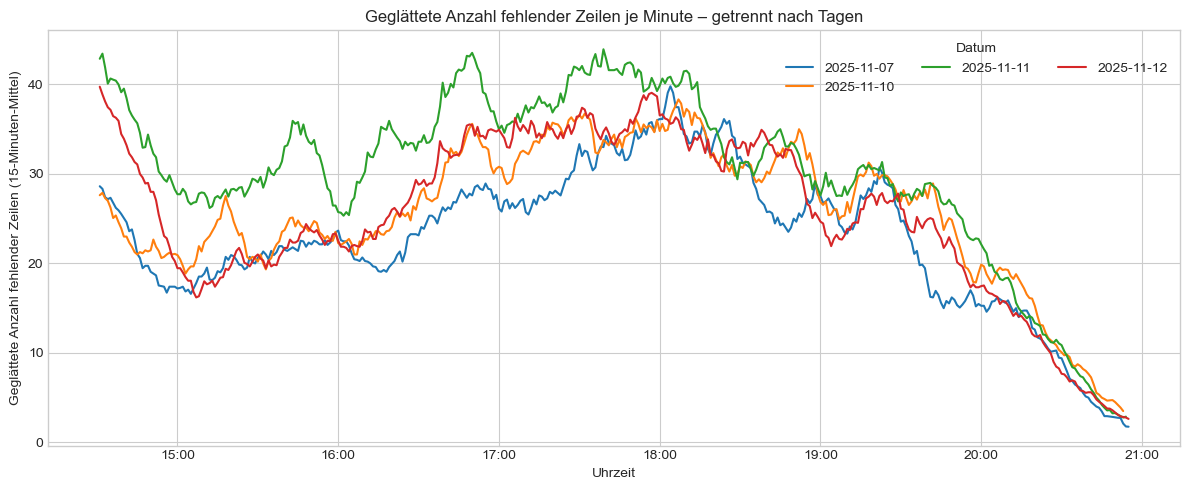

In [48]:
# Tages-Coverage
daily_rows = df.groupby("date").size().rename("rows_total")
daily_missing = df.isna().any(axis=1).groupby(df["date"]).sum().rename("rows_missing")

coverage = pd.concat([daily_rows, daily_missing], axis=1)
coverage["missing_%"] = 100 * coverage["rows_missing"] / coverage["rows_total"]

print("Tages-Coverage (Zeilen gesamt / Fehlzeilen / Prozent):")
display(coverage.sort_index())

# Fehlwerte über den Tag, getrennt nach Datum
missing_time_by_day = (
    df[df.isna().any(axis=1)]
      .groupby(["date", "time"])
      .size()
      .rename("count")
      .reset_index()
)

# time -> datetime (Dummy-Datum für x-Achse)
missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))

# Glättung (moving average über ~15 Minuten)
# dafür Index als Zeitreihe pro Tag sortieren
smoothed = []
for d, sub in missing_time_by_day.groupby("date"):
    sub = sub.sort_values("time_dt").copy()
    sub["count_smooth"] = sub["count"].rolling(window=15, min_periods=1, center=True).mean()
    smoothed.append(sub)
missing_time_smoothed = pd.concat(smoothed, ignore_index=True)

# Plot: geglättete Kurven
plt.figure(figsize=(12, 5))
for d, sub in missing_time_smoothed.groupby("date"):
    plt.plot(sub["time_dt"], sub["count_smooth"], label=str(d))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.title("Geglättete Anzahl fehlender Zeilen je Minute – getrennt nach Tagen")
plt.xlabel("Uhrzeit")
plt.ylabel("Geglättete Anzahl fehlender Zeilen (15-Minuten-Mittel)")
plt.legend(title="Datum", ncol=min(3, coverage.shape[0]))
plt.tight_layout()
plt.show()


Es ist ein klarer Trend zu erkennen in den fehlenden Daten, jedoch liegt die Erklärung dazu nicht im Rahmen dieses Projekts. Die Hauptsache für die EDA dieses Projekts ist, dass es keinen auffälligen Ausreisser (Tag) vorkommt. Der Trend ist im folgenden Histogramm besser zu erkennen:

C:\Users\ilija\AppData\Local\Temp\ipykernel_34948\2440158661.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_df["time_dt"] = pd.to_datetime(missing_time_df["time_only"].astype(str))


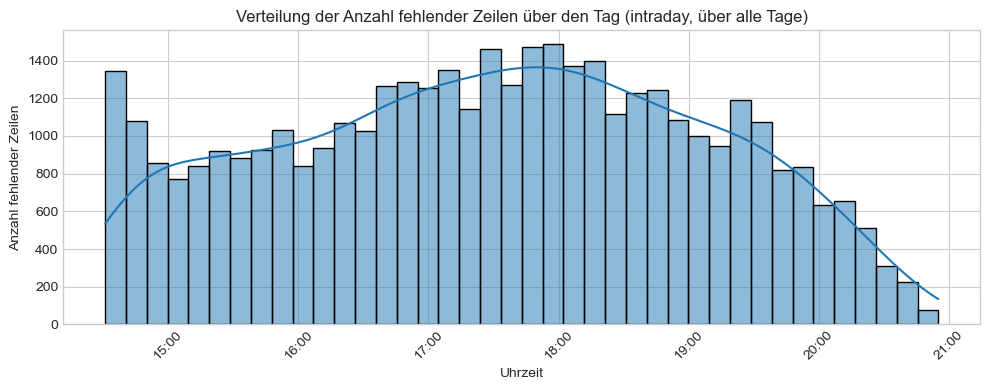

In [49]:
# Aggregiere fehlende Zeilen pro Zeitstempel (mehrere Tage)
missing_by_timestamp = df[df.isna().any(axis=1)].groupby("datetime").size().rename("count")
missing_time_df = missing_by_timestamp.reset_index()

# Histogramm + KDE über den Tag (wir betrachten Uhrzeit-Komponente)
missing_time_df["time_only"] = missing_time_df["datetime"].dt.time
missing_time_df["time_dt"] = pd.to_datetime(missing_time_df["time_only"].astype(str))

plt.figure(figsize=(10,4))
sns.histplot(
    data=missing_time_df.sort_values("time_dt"),
    x="time_dt",
    weights="count",
    bins=40,
    kde=True
)
plt.title("Verteilung der Anzahl fehlender Zeilen über den Tag (intraday, über alle Tage)")
plt.xlabel("Uhrzeit")
plt.ylabel("Anzahl fehlender Zeilen")
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Verteilung fehlender Daten über den Tag

- Hier wird mit einem **Histogramm und einer KDE-Kurve** (Dichtekurve) dargestellt,  
  zu welchen Uhrzeiten die meisten fehlenden Daten auftreten.  
- Die X-Achse zeigt die Uhrzeit, die Y-Achse die Anzahl fehlender Zeilen zu diesem Zeitpunkt.  
  Alle Daten stammen von einem einzigen Tag.
- Aus der Grafik lässt sich erkennen, dass fehlende Werte nicht gleichmäßig über den Tag verteilt sind.  
  Besonders am **Nachmittag (zwischen ca. 17:00 und 19:00 Uhr)** treten mehr fehlende Daten auf,  
  während vormittags und vor allem spätabends deutlich weniger Lücken vorkommen.

Das deutet darauf hin, dass es zu bestimmten Handelszeiten häufiger Datenlücken gab

### 3.2.3. Datenlücken

Im folgenden wird untersucht, ob und wie diese fehlenden Daten konsekutiv vorkommen. Diese Lücken sind ein Problem, falls sie zu gross werden. Es ist zu bemerken, dass die Zahlen hier nicht auf den Tag aggregiert wurden, wie vorhin.

Gefundene Lücken insgesamt: 34881



,gap_len,rel_change
count,34881.000000,34881.000000
mean,2.399272,0.000024
std,1.046542,0.001130
min,2.000000,-0.020662
25%,2.000000,-0.000450
50%,2.000000,0.000000
75%,2.000000,0.000491
max,27.000000,0.018582


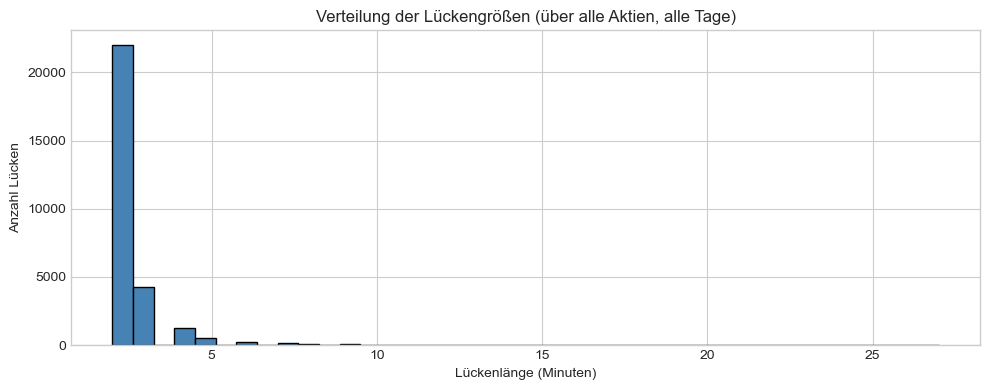

In [50]:
def analyse_nan_luecken_global(df):
    """
    Findet konsekutive NaN-Blöcke im 'close' je Symbol über den gesamten Datensatz.
    Für jeden Block wird (nahezu) die Lückenlänge in Minuten und die relative
    Preisänderung zwischen dem Wert direkt vor der Lücke und direkt nach der Lücke berechnet.
    """
    normal_step = pd.Timedelta(minutes=1)
    all_gaps = []

    for ticker, data in df.groupby("symbol"):
        data = data.sort_values("datetime").reset_index(drop=True)
        is_nan_close = data["close"].isna()
        if not is_nan_close.any():
            continue

        nan_idx = np.where(is_nan_close)[0]
        gap_blocks = np.split(nan_idx, np.where(np.diff(nan_idx) > 1)[0] + 1)

        for block in gap_blocks:
            # Indizes direkt vor und nach der Lücke
            gap_start_idx = block[0] - 1
            gap_end_idx   = block[-1] + 1
            if gap_start_idx < 0 or gap_end_idx >= len(data):
                continue

            t_before = data.loc[gap_start_idx, "datetime"]
            t_after  = data.loc[gap_end_idx, "datetime"]
            close_before = data.loc[gap_start_idx, "close"]
            close_after  = data.loc[gap_end_idx, "close"]

            # Schutz: angrenzende Werte müssen gültig sein
            if pd.isna(close_before) or pd.isna(close_after):
                continue

            # Lückenlänge anhand der Zeitdifferenz (~ Minuten)
            gap_len = (t_after - t_before) / normal_step
            rel_change = (close_after - close_before) / close_before

            all_gaps.append({
                "symbol": ticker,
                "gap_len": float(gap_len),
                "rel_change": float(rel_change),
            })

    return pd.DataFrame(all_gaps)

# --- Analyse ausführen ---
nan_gaps_all = analyse_nan_luecken_global(df)

print(f"Gefundene Lücken insgesamt: {len(nan_gaps_all)}\n")
display(nan_gaps_all.describe())

# --- Verteilung der Lückengrößen ---
plt.figure(figsize=(10,4))
plt.hist(nan_gaps_all["gap_len"], bins=40, color="steelblue", edgecolor="black")
plt.title("Verteilung der Lückengrößen (über alle Aktien, alle Tage)")
plt.xlabel("Lückenlänge (Minuten)")
plt.ylabel("Anzahl Lücken")
plt.tight_layout()
plt.show()


**Analyse der NaN-Lücken im Datensatz**

- In dieser Analyse werden **Lücken (NaN-Werte)** in den Kursdaten aller Aktien untersucht.  
  Die Funktion `analyse_nan_luecken_global(df)` sucht für jede Aktie zusammenhängende Bereiche mit fehlenden Werten und berechnet die Länge der Lücke in Minuten und die relative Preisänderung zwischen den Zeitpunkten davor und danach.

- Die statistische Auswertung zeigt, dass die meisten Lücken kurz sind und der Datensatz sollte deshalb kein Problem darstellen.

- Das Histogramm visualisiert die Verteilung der Lückengrößen. Der Großteil der Lücken beträgt nur 2 Minuten, längere Ausfälle sind sehr selten. Das deutet darauf hin, dass kurze Datenunterbrechungen regelmäßig, aber nicht gravierend auftreten. Da das Histrogramm nicht besonders leserlich ist, gibt es noch den folgenden Code.

In [51]:
gap_counts = nan_gaps_all["gap_len"].value_counts().sort_index()
gap_counts = gap_counts[gap_counts.index >= 0]

print("Anzahl vorkommender Lücken pro Lückengröße (in Minuten):\n")
for gap_len, count in gap_counts.items():
    print(f"{gap_len:>4} Minuten : {count}x")


Anzahl vorkommender Lücken pro Lückengröße (in Minuten):

 2.0 Minuten : 26920x
 3.0 Minuten : 5154x
 4.0 Minuten : 1533x
 5.0 Minuten : 588x
 6.0 Minuten : 267x
 7.0 Minuten : 158x
 8.0 Minuten : 96x
 9.0 Minuten : 71x
10.0 Minuten : 27x
11.0 Minuten : 16x
12.0 Minuten : 19x
13.0 Minuten : 7x
14.0 Minuten : 4x
15.0 Minuten : 7x
16.0 Minuten : 1x
17.0 Minuten : 5x
18.0 Minuten : 2x
19.0 Minuten : 1x
20.0 Minuten : 1x
21.0 Minuten : 1x
23.0 Minuten : 1x
27.0 Minuten : 2x


Die grossen Lücken stellen ein Problem dar, deshalb wird als nächstes identifiziert, welche Aktien grosse Lücken haben.

Der unten stehende Codeblock filtert aus der zuvor berechneten Tabelle nan_gaps_all alle Lücken mit einer Länge größer als 5 Minuten heraus und identifiziert die betroffenen Aktien. Anschließend werden die Anzahl betroffener Ticker ausgegeben und für jeden Ticker die Anzahl der langen Lücken sowie die maximale Lückenlänge angezeigt.

In [52]:
long_gaps = nan_gaps_all[nan_gaps_all["gap_len"] > 5]
symbols_with_long_gaps = np.sort(long_gaps["symbol"].unique())

print(f"Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: {len(symbols_with_long_gaps)}\n")
print("Aktien mit langen Lücken (> 5 Minuten):")
for sym in symbols_with_long_gaps:
    sub = long_gaps[long_gaps["symbol"] == sym]
    n_luecken = len(sub)
    max_gap = sub["gap_len"].max()
    print(f"  {sym} — {n_luecken} Lücken (max. {int(max_gap)} Minuten)")


Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: 68

Aktien mit langen Lücken (> 5 Minuten):
  AIZ — 57 Lücken (max. 15 Minuten)
  ALGN — 1 Lücken (max. 7 Minuten)
  ALLE — 6 Lücken (max. 7 Minuten)
  AMP — 1 Lücken (max. 6 Minuten)
  ATO — 4 Lücken (max. 8 Minuten)
  AVY — 14 Lücken (max. 9 Minuten)
  AZO — 1 Lücken (max. 7 Minuten)
  BIIB — 1 Lücken (max. 6 Minuten)
  BR — 4 Lücken (max. 9 Minuten)
  BXP — 3 Lücken (max. 6 Minuten)
  CBOE — 1 Lücken (max. 6 Minuten)
  CINF — 30 Lücken (max. 13 Minuten)
  CRL — 3 Lücken (max. 8 Minuten)
  DOV — 1 Lücken (max. 7 Minuten)
  DPZ — 1 Lücken (max. 8 Minuten)
  DRI — 1 Lücken (max. 6 Minuten)
  DVA — 1 Lücken (max. 8 Minuten)
  EME — 3 Lücken (max. 9 Minuten)
  EPAM — 2 Lücken (max. 7 Minuten)
  ERIE — 88 Lücken (max. 17 Minuten)
  FRT — 1 Lücken (max. 7 Minuten)
  GL — 18 Lücken (max. 12 Minuten)
  GPC — 4 Lücken (max. 6 Minuten)
  GRMN — 2 Lücken (max. 6 Minuten)
  GWW — 28 Lücken (max. 15 Minuten)
  HIG — 1 Lücken (max. 6 Minuten)
 

Dies zeigt, dass grosse Lücken nicht selten vorkommen in unserem Datensatz. Um das genauer zu untersuchen, werden im folgenden Code gezählt wie viele Aktien eine bestimmte Datenlückenlänge haben und anschliessend geplottet.

Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten (erste 20 Zeilen):

    gap_length_min  n_stocks
0                1       369
1                2       369
2                3       242
3                4       153
4                5       107
5                6        68
6                7        46
7                8        35
8                9        23
9               10        11
10              11        10
11              12        10
12              13         8
13              14         6
14              15         6
15              16         4
16              17         4
17              18         3
18              19         3
19              20         2


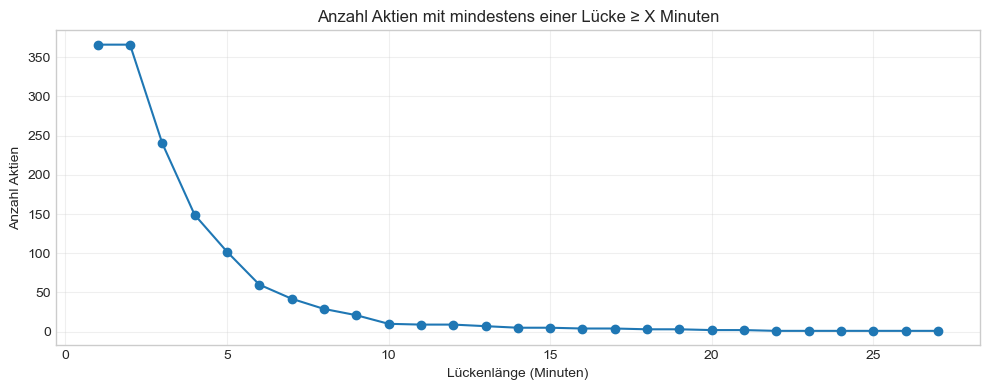

In [53]:
# (Sicherstellen: ganze Minuten)
nan_gaps_all["gap_len"] = nan_gaps_all["gap_len"].round().astype(int)

max_gap_per_symbol = nan_gaps_all.groupby("symbol")["gap_len"].max()
max_len = int(max_gap_per_symbol.max()) if len(max_gap_per_symbol) else 0

minutes = np.arange(1, max_len + 1) if max_len > 0 else np.array([], dtype=int)
stocks_with_min_gap = [(max_gap_per_symbol >= m).sum() for m in minutes] if minutes.size else []

gap_stats = pd.DataFrame({"gap_length_min": minutes, "n_stocks": stocks_with_min_gap})

print("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten (erste 20 Zeilen):\n")
print(gap_stats.head(20))

# Plot (nur wenn es Daten gibt)
if len(gap_stats):
    plt.figure(figsize=(10,4))
    plt.plot(gap_stats["gap_length_min"], gap_stats["n_stocks"], marker="o")
    plt.title("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten")
    plt.xlabel("Lückenlänge (Minuten)")
    plt.ylabel("Anzahl Aktien")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


Die Form des Plots ist nicht überraschend. Jedoch kann aufgrund der Abflachung entschieden werden, wo es Sinn macht eine Grenze zu setzen. Diese Grenze definiert welche Datenlücken aufgefüllt werden und welche Aktien entfernt werden aus dem Datensatz.

Es wurde entschieden, dass die Aktien mit Datenlücken, die mindestens 6 Minuten lang sind, entfernt werden.

### 3.2.3. Datenbereinigung
Da nun festgestellt wurde wie die Datenlücken aussehen werden Aktien mit zu grossen Datenlücken entfernt.

In [54]:
# maximale Lücke pro Symbol
max_gap_per_symbol = nan_gaps_all.groupby("symbol")["gap_len"].max()

# alle Symbole mit >= 6 Minuten Lücke
symbols_with_long_gaps = max_gap_per_symbol[max_gap_per_symbol >= 6].index
print(f"Anzahl Aktien mit mindestens einer Lücke ≥ 6 Minuten: {len(symbols_with_long_gaps)}")

# Hauptraum säubern: entferne diese Symbole
df_clean = df[~df["symbol"].isin(symbols_with_long_gaps)].copy()
df_clean = df_clean.sort_values("datetime").reset_index(drop=True)

print(f"Verbleibende Aktien nach Filterung: {df_clean['symbol'].nunique()}")
print(f"Zeilen nach Filterung: {len(df_clean):,}")


Anzahl Aktien mit mindestens einer Lücke ≥ 6 Minuten: 68
Verbleibende Aktien nach Filterung: 436
Zeilen nach Filterung: 849,633


Die kleinen Datenlücken werden im folgenden Schritt bereinigt. Datenlücken werden gefüllt indem, sie interpoliert werden und in Edge-Cases wird von vorne/hinten aufgefüllt. Dazu wird die ('close_filled') hinzugefügt, um die Daten nicht zu verfälschen.

In [55]:
# Sortierung und Typ-Sicherung
df_clean = df_clean.sort_values(["symbol", "datetime"]).copy()
df_clean["datetime"] = pd.to_datetime(df_clean["datetime"], errors="coerce")

def fill_close_gaps(group):
    """
    Interpoliert fehlende Close-Werte (zeitbasiert) und füllt Ränder.
    1. Zeitliche Interpolation für innenliegende NaNs
    2. Vorwärts-/Rückwärtsfüllung für Randbereiche
    """
    group = group.sort_values("datetime").set_index("datetime")
    s = group["close"]

    # Innenliegende Lücken glätten
    s_interp = s.interpolate(method="time", limit_area="inside")

    # Ränder auffüllen
    s_filled = s_interp.bfill().ffill()

    group["close_filled"] = s_filled
    return group.reset_index()

# Auf alle Symbole anwenden
df_filled = df_clean.groupby("symbol", group_keys=False).apply(fill_close_gaps)

# Kontrolle
print("Fehlende Werte im Original (gefiltert):", df_clean["close"].isna().sum())
print("Fehlende Werte in close_filled:", df_filled["close_filled"].isna().sum())


Fehlende Werte im Original (gefiltert): 18979
Fehlende Werte in close_filled: 0


C:\Users\ilija\AppData\Local\Temp\ipykernel_34948\1722278231.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_filled = df_clean.groupby("symbol", group_keys=False).apply(fill_close_gaps)


Da nun keine Datenlücken vorkommen, wird nun die Länge Daten pro Aktie analysiert.

In [56]:
# Anzahl Zeilen je Symbol
lengths = df_filled.groupby("symbol").size().sort_values()

print("\nHäufigste Längen:")
print(lengths.value_counts().sort_index())

df_filled.head()


Häufigste Längen:
391       1
782       1
1562      2
1563      2
1564    438
Name: count, dtype: int64


,datetime,symbol,open,high,low,close,volume,date,time,close_filled
0,2025-11-07 14:30:00,A,146.520004,147.119995,145.729996,145.729996,13361.0,2025-11-07,14:30:00,145.729996
1,2025-11-07 14:31:00,A,NaN,NaN,NaN,NaN,NaN,2025-11-07,14:31:00,145.909996
2,2025-11-07 14:32:00,A,146.089996,146.089996,146.089996,146.089996,427.0,2025-11-07,14:32:00,146.089996
3,2025-11-07 14:33:00,A,NaN,NaN,NaN,NaN,NaN,2025-11-07,14:33:00,146.069847
4,2025-11-07 14:34:00,A,146.049698,146.049698,146.049698,146.049698,1387.0,2025-11-07,14:34:00,146.049698


Vereinzelte Aktien haben ausreissende Datenlängen. Diese sind sehr problematisch. Zunächst wird untersucht, um welche Aktien es sich handelt.

In [57]:
expected_length = lengths.mode().iloc[0]  # häufigste Länge als Referenz
print(f"Erwartete Anzahl Zeilen pro Symbol: {expected_length}\n")

# Abweichungen finden
bad_symbols = lengths[lengths != expected_length]

if bad_symbols.empty:
    print("Alle Symbole haben die erwartete Länge – keine Entfernung nötig.")
    symbols_to_drop = []
else:
    print(f"{len(bad_symbols)} Symbole mit abweichender Länge gefunden:\n")
    display(bad_symbols)

    # Liste der zu entfernenden Symbole
    symbols_to_drop = bad_symbols.index.tolist()

    print(f"\nZu entfernende Symbole (für Zelle 12):")
    print(symbols_to_drop)


Erwartete Anzahl Zeilen pro Symbol: 1955

7 Symbole mit abweichender Länge gefunden:



symbol
FISV     391
FI       782
DD      1952
ZTS     1952
CBRE    1953
TT      1954
FICO    1954
dtype: int64


Zu entfernende Symbole (für Zelle 12):
['FISV', 'FI', 'DD', 'ZTS', 'CBRE', 'TT', 'FICO']


Es kann nicht erklärt werden, weshalb es hier Ausreisser gibt. Diese wenigen Aktien werden geopfert für einen guten Datensatz.

In [58]:
n_before = df_filled["symbol"].nunique()
df_filled = df_filled[~df_filled["symbol"].isin(symbols_to_drop)].copy()
n_after = df_filled["symbol"].nunique()

print(f"Entfernte Symbole: {symbols_to_drop}")
print(f"Verbleibende Aktien: {n_after} (vorher: {n_before})")

Entfernte Symbole: ['FISV', 'FI', 'DD', 'ZTS', 'CBRE', 'TT', 'FICO']
Verbleibende Aktien: 429 (vorher: 436)


Die Daten wurden nun bereinigt. Eine kurze Überprüfung zeigt, dass noch genug Daten vorhanden sind. Somit sind sowohl Menge und Qualität gesichert.

In [59]:
symbols_before = set(df["symbol"].unique())
symbols_after = set(df_filled["symbol"].unique())
removed_symbols = symbols_before - symbols_after
print("Anzahl Aktien zu Beginn:", len(symbols_before))
print("Anzahl Aktien nach Bereinigung: " + str(len(symbols_after)) + "\n")
print("Entfernte Aktien: " + str(len(removed_symbols)))
print(sorted(removed_symbols))


Anzahl Aktien zu Beginn: 504
Anzahl Aktien nach Bereinigung: 429

Entfernte Aktien: 75
['AIZ', 'ALGN', 'ALLE', 'AMP', 'ATO', 'AVY', 'AZO', 'BIIB', 'BR', 'BXP', 'CBOE', 'CBRE', 'CINF', 'CRL', 'DD', 'DOV', 'DPZ', 'DRI', 'DVA', 'EME', 'EPAM', 'ERIE', 'FI', 'FICO', 'FISV', 'FRT', 'GL', 'GPC', 'GRMN', 'GWW', 'HIG', 'HII', 'HWM', 'IDXX', 'IEX', 'IQV', 'J', 'JBL', 'JKHY', 'L', 'LDOS', 'MCK', 'MHK', 'MLM', 'MSCI', 'MTD', 'NDSN', 'NVR', 'NWS', 'ODFL', 'PKG', 'PNR', 'PRU', 'PTC', 'RJF', 'RL', 'SBAC', 'SJM', 'SNA', 'STE', 'STLD', 'TDY', 'TKO', 'TPL', 'TRMB', 'TT', 'TYL', 'UHS', 'ULTA', 'WAB', 'WDAY', 'WSM', 'WTW', 'WYNN', 'ZTS']


## 3.3. Paarsuche

Die Paarsuche bildet einen zentralen Schritt im Pairs Trading. Ziel ist es, Aktienpaare zu identifizieren, deren Kursverläufe langfristig ähnliche Muster aufweisen und sich daher potenziell für eine mean-reversion-basierte Handelsstrategie eignen.

**Vorgehensweise:**

Auf Basis der bereinigten und fehlwertfreien Kursdaten wird zunächst eine gemeinsame Preis-Matrix erstellt. Diese enthält für jeden Zeitpunkt die entsprechenden Preise aller betrachteten Symbole. Die Matrix dient als Grundlage für weitere Analysen wie die Berechnung von Korrelationen oder Distanzmaßen zwischen Kursreihen.

**Auswahlprozess:**

Mithilfe statistischer Methoden werden aus der Preis-Matrix Paare hervorgehoben, die über den gesamten Zeitraum hinweg ein stabiles Verhältnis zueinander aufweisen. Diese Paare werden als potenzielle Kandidaten für das Pairs Trading markiert. Eine endgültige Bewertung oder ein Vergleich erfolgt bewusst erst im späteren Fazit.


In [60]:
# Pivot-Tabelle: Zeilen = Zeit, Spalten = Symbol, Werte = Close
price_matrix = df_filled.pivot(index="datetime", columns="symbol", values="close_filled")

# Logarithmieren (reduziert Trends, stabilisiert Varianz)
log_prices = np.log(price_matrix)

### 3.3.1. Korrelation

Zur Einschränkung der möglichen Pair-Trading-Kandidaten wird zunächst die Korrelationsmatrix der logarithmierten Preise berechnet. Anschließend werden Paare mit sehr hoher Korrelation (r > 0.97) gefiltert.

Für die Visualisierung wird eine Heatmap der **Top-N Aktien** mit den höchsten durchschnittlichen Korrelationen erstellt. Die Diagonale wird maskiert, um nur relevante Off-Diagonal-Korrelationen darzustellen. Dies ermöglicht einen schnellen Überblick über stark miteinander korrelierende Aktien, die für weitere Analysen in Frage kommen.


97 stark korrelierte Paare gefunden (r > 0.97)

Min/Max der Off-Diagonal-Korrelationen: 0.8046931890273757 0.9802944642740979


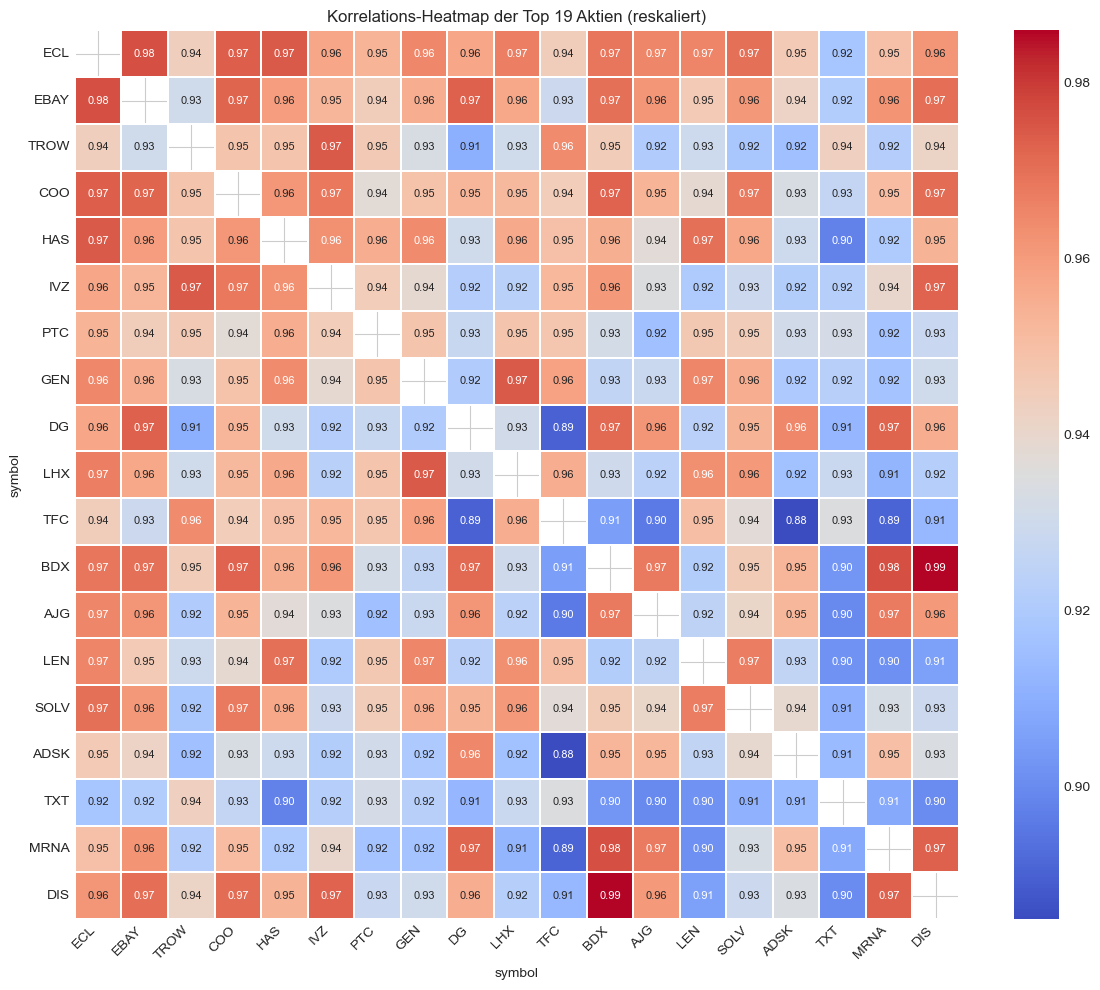

In [61]:
corr = log_prices.corr()

# Stark korrelierte Paare finden
strong_corr_pairs = [
    (i, j)
    for i in corr.columns
    for j in corr.columns
    if i < j and corr.loc[i, j] > 0.97
]
print(f"{len(strong_corr_pairs)} stark korrelierte Paare gefunden (r > 0.97)")

# Mittelwerte der Korrelationen
mean_corr = corr.mean().sort_values(ascending=False)

# Top-N Aktien mit höchsten durchschnittlichen Korrelationen
top_n_heatmap = 19
top_symbols = mean_corr.head(top_n_heatmap).index

# Submatrix der Top-N Aktien
corr_sub = corr.loc[top_symbols, top_symbols]

# Diagonale maskieren (1.0-Werte)
mask = np.eye(len(corr_sub), dtype=bool)

# Off-Diagonal-Werte bestimmen
offdiag = corr_sub.where(~pd.DataFrame(mask, index=corr_sub.index, columns=corr_sub.columns))
vmin = offdiag.min().min()
vmax = offdiag.max().max()
print("\nMin/Max der Off-Diagonal-Korrelationen:", vmin, vmax)

# Heatmap (mit Korrelationswerten / rho)
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_sub,
    mask=mask,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    linewidths=0.2,
    annot_kws={"size": 8}
)
plt.title(f"Korrelations-Heatmap der Top {top_n_heatmap} Aktien (reskaliert)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Vergleich mit Klassischen Aktien-Indikatoren



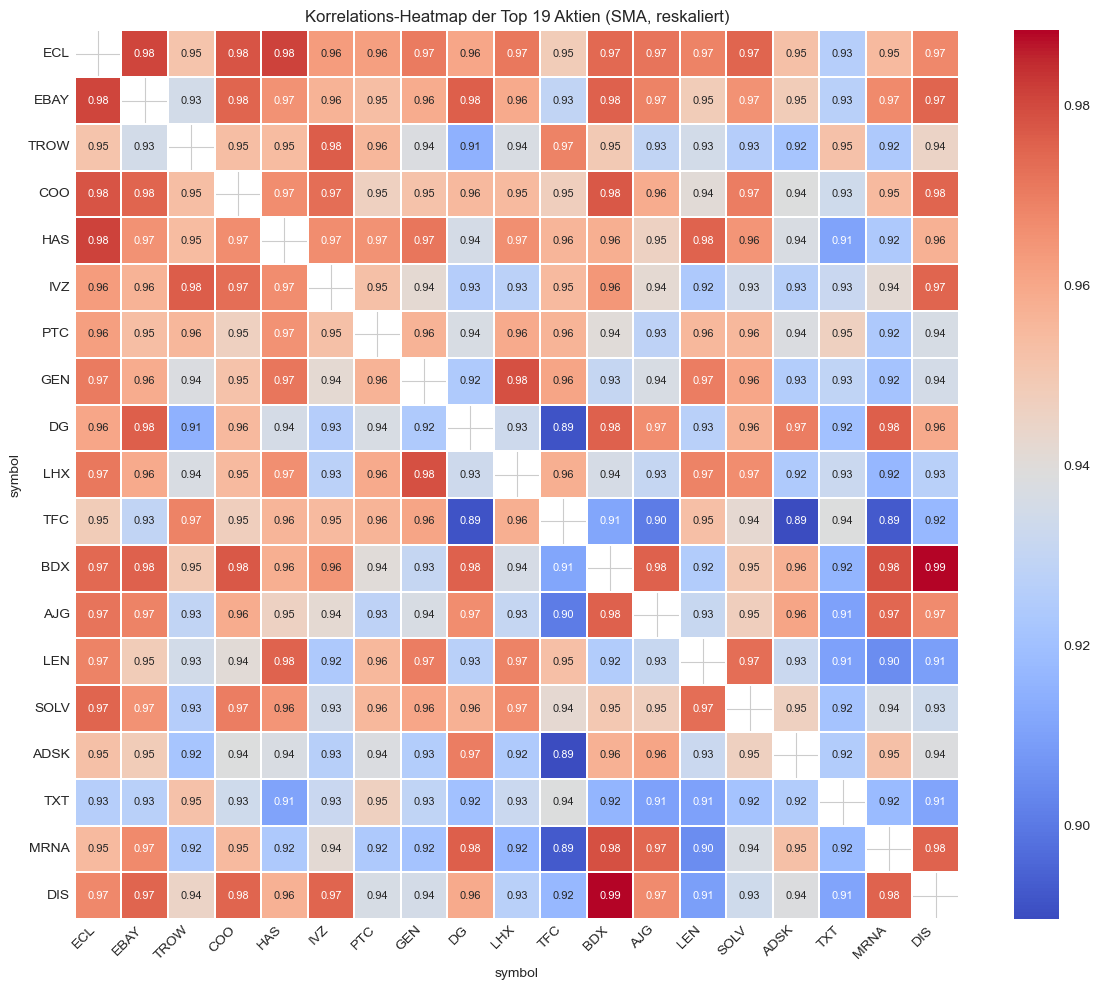

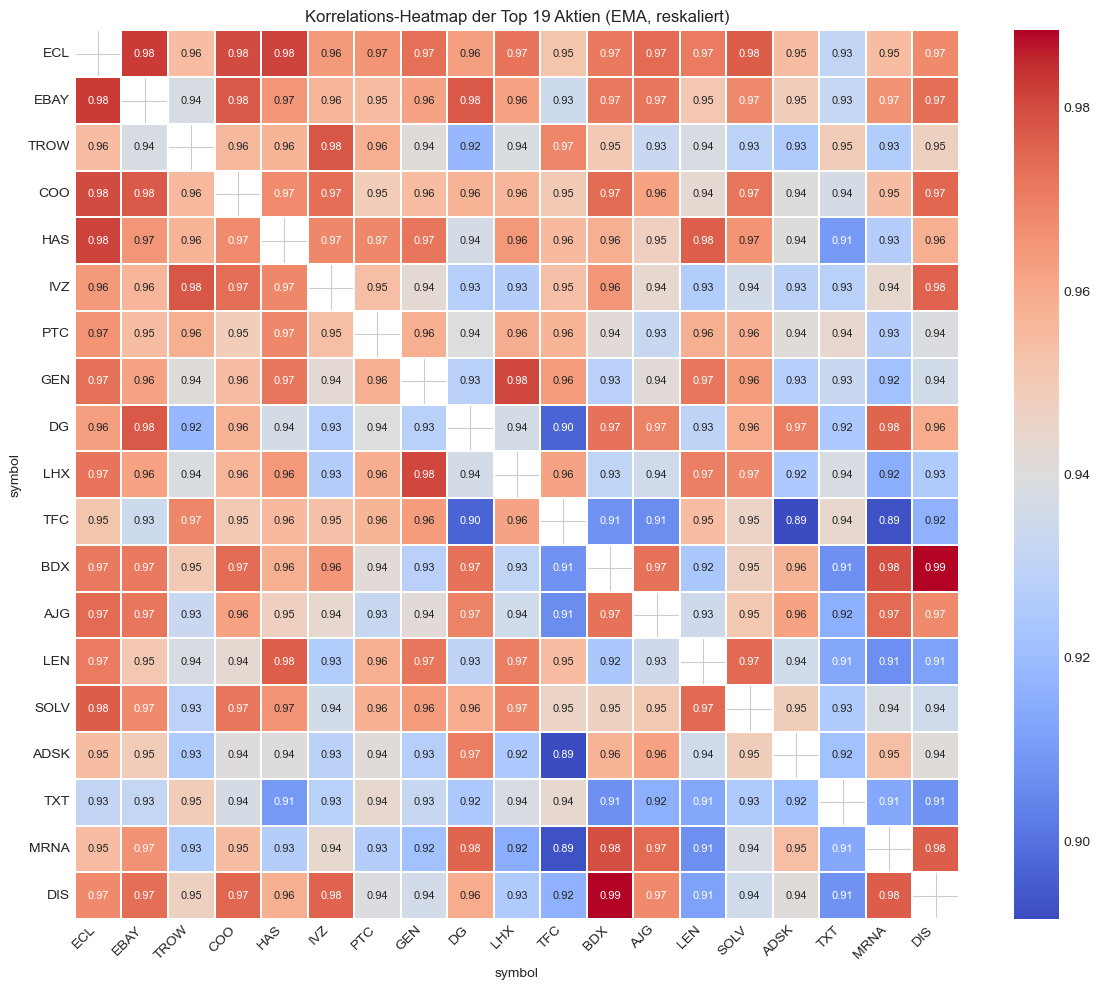

In [65]:

# Berechne den 20-Tage SMA für jede Aktie
df_filled["SMA_20"] = df_filled.groupby("symbol")["close_filled"].transform(lambda x: x.rolling(20).mean())

# Berechne den 20-Tage EMA für jede Aktie
df_filled["EMA_20"] = df_filled.groupby("symbol")["close_filled"].transform(lambda x: x.ewm(span=20).mean())

# Pivotieren der Daten für SMA_20
sma_data = df_filled.pivot_table(index="datetime", columns="symbol", values="SMA_20")

# Pivotieren der Daten für EMA_20
ema_data = df_filled.pivot_table(index="datetime", columns="symbol", values="EMA_20")

# Berechne die Korrelation der SMA- und EMA-Werte
sma_corr = sma_data.corr()  # Korrelation der SMA-Werte
ema_corr = ema_data.corr()  # Korrelation der EMA-Werte

# Liste der Aktien in der gleichen Reihenfolge wie im Bild
symbols_in_order = [
    "ECL", "EBAY", "TROW", "COO", "HAS", "IVZ", "PTC", "GEN", "DG", "LHX",
    "TFC", "BDX", "AJG", "LEN", "SOLV", "ADSK", "TXT", "MRNA", "DIS"
]

# Submatrix der Korrelationen für diese spezifischen Aktien
sma_corr_sub = sma_corr.loc[symbols_in_order, symbols_in_order]
ema_corr_sub = ema_corr.loc[symbols_in_order, symbols_in_order]

# Maske für die Diagonale (1.0-Werte)
mask = np.eye(len(sma_corr_sub), dtype=bool)

# Berechne den minimalen und maximalen Wert der Off-Diagonal-Korrelationen
offdiag_sma = sma_corr_sub.where(~pd.DataFrame(mask, index=sma_corr_sub.index, columns=sma_corr_sub.columns))
offdiag_ema = ema_corr_sub.where(~pd.DataFrame(mask, index=ema_corr_sub.index, columns=ema_corr_sub.columns))

vmin_sma = offdiag_sma.min().min()
vmax_sma = offdiag_sma.max().max()

vmin_ema = offdiag_ema.min().min()
vmax_ema = offdiag_ema.max().max()

# Heatmap für die SMA-Korrelationen
plt.figure(figsize=(12, 10))
sns.heatmap(
    sma_corr_sub,
    mask=mask,
    cmap="coolwarm",
    vmin=vmin_sma,
    vmax=vmax_sma,
    annot=True,
    fmt=".2f",
    linewidths=0.2,
    annot_kws={"size": 8}
)
plt.title(f"Korrelations-Heatmap der Top 19 Aktien (SMA, reskaliert)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Heatmap für die EMA-Korrelationen
plt.figure(figsize=(12, 10))
sns.heatmap(
    ema_corr_sub,
    mask=mask,
    cmap="coolwarm",
    vmin=vmin_ema,
    vmax=vmax_ema,
    annot=True,
    fmt=".2f",
    linewidths=0.2,
    annot_kws={"size": 8}
)
plt.title(f"Korrelations-Heatmap der Top 19 Aktien (EMA, reskaliert)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

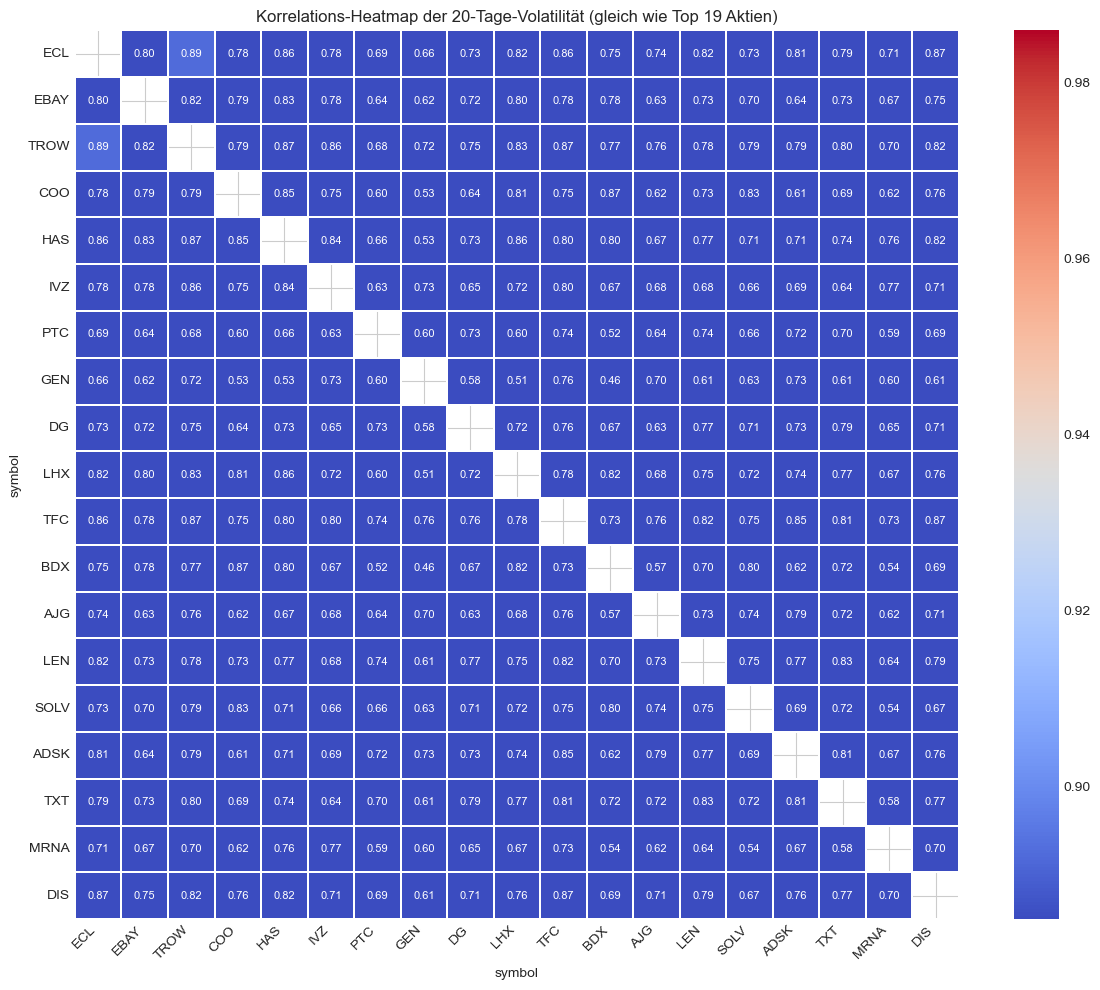

In [68]:
# Log-Return sauber berechnen
df_filled["log_return"] = (
    df_filled
    .groupby("symbol")["close_filled"]
    .transform(lambda x: np.log(x / x.shift(1)))
)

# 20-Perioden-Volatilität (Rolling-Std) pro Aktie
df_filled["volatility_20"] = (
    df_filled
    .groupby("symbol")["log_return"]
    .transform(lambda x: x.rolling(20).std())
)

vol_data = df_filled.pivot_table(index="datetime", columns="symbol", values="volatility_20")

vol_corr = vol_data.corr()

vol_corr_sub = vol_corr.loc[symbols_in_order, symbols_in_order]

plt.figure(figsize=(12, 10))
sns.heatmap(
    vol_corr_sub,
    mask=mask,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    linewidths=0.2,
    annot_kws={"size": 8}
)
plt.title("Korrelations-Heatmap der 20-Tage-Volatilität (gleich wie Top 19 Aktien)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### 3.3.2. Cointegration & Spread

Korrelation allein reicht nicht aus, um stabile Paare zu identifizieren. Daher wird für jedes stark korrelierte Paar täglich ein **Engle-Granger-Cointegrationstest** durchgeführt.  
Nur wenn zwei Preisreihen cointegrated sind, bewegen sie sich langfristig gemeinsam – eine zentrale Voraussetzung für Pair-Trading-Strategien.

Der Code prüft für jeden Tag, ob genügend Intraday-Daten vorhanden sind, richtet beide Serien zeitlich aus und berechnet anschließend das tägliche p-Value. Die Ergebnisse werden in `daily_coint_df` gespeichert und bilden die Grundlage für die spätere Spread-Berechnung.


In [67]:
# Sicherstellen, dass der Index zeitlich sortiert ist
log_prices = log_prices.sort_index()

# Liste aller Tage (nur Datum, ohne Zeitanteil)
unique_days = log_prices.index.normalize().unique()

daily_coint_records = []

# Mindestanzahl Beobachtungen pro Tag / Paar (sonst ist Cointegration-Test fragwürdig)
min_obs_per_day = 30

for current_day in unique_days:
    # Alle intraday-Daten für diesen Tag
    day_mask = log_prices.index.normalize() == current_day
    day_prices = log_prices.loc[day_mask, :]

    if len(day_prices) < min_obs_per_day:
        continue  # zu wenig Daten für diesen Tag insgesamt

    for s1, s2 in strong_corr_pairs:
        # Serien für die beiden Symbole an diesem Tag
        s1_series = day_prices[s1].dropna()
        s2_series = day_prices[s2].dropna()

        # Nach gemeinsamen Zeitstempeln ausrichten
        aligned = pd.concat([s1_series, s2_series], axis=1, join="inner").dropna()
        aligned.columns = ["s1", "s2"]

        if len(aligned) < min_obs_per_day:
            continue  # zu wenig gemeinsame Datenpunkte

        # Engle-Granger Cointegrationstest
        try:
            score, pvalue, _ = coint(aligned["s1"], aligned["s2"])
        except Exception as e:
            # Falls der Test mal numerisch scheitert
            print(f"Cointegration-Fehler am {current_day.date()} für {s1}-{s2}: {e}")
            continue

        daily_coint_records.append({
            "date": current_day,   # nur das Datum, nicht die Uhrzeit
            "symbol1": s1,
            "symbol2": s2,
            "pvalue": pvalue
        })

daily_coint_df = pd.DataFrame(daily_coint_records)

if daily_coint_df.empty:
    print("WARNUNG: daily_coint_df ist leer – prüfe Daten, min_obs_per_day oder strong_corr_pairs.")
else:
    daily_coint_df["date"] = pd.to_datetime(daily_coint_df["date"])
    daily_coint_df = daily_coint_df.sort_values(["symbol1", "symbol2", "date"]).reset_index(drop=True)
    print(f"{len(daily_coint_df)} tägliche Cointegrationseinträge berechnet.")
    display(daily_coint_df.head())


485 tägliche Cointegrationseinträge berechnet.


,date,symbol1,symbol2,pvalue
0,2025-11-07,ABBV,ABT,0.156587
1,2025-11-10,ABBV,ABT,0.387149
2,2025-11-11,ABBV,ABT,0.089552
3,2025-11-12,ABBV,ABT,0.006688
4,2025-11-13,ABBV,ABT,0.700641


Nach der täglichen Cointegrationsberechnung wird evaluiert, welche Paare über einen längeren Zeitraum hinweg **stabil cointegrated** sind.  
Dazu werden alle täglichen Ergebnisse pro Paar aggregiert:

- `n_days`: Anzahl der Tage mit verfügbaren Messungen  
- `n_sig_days`: Anzahl der Tage, an denen das p-Value unter der Signifikanzschwelle (p < 0.05) lag  
- `mean_p`, `std_p`: durchschnittliches bzw. die Streuung der p-Werte  
- `min_p`, `max_p`: beste und schlechteste beobachtete p-Werte

Aus dem Verhältnis  
$$
\text{consistency} = \frac{n_\text{sig\_days}}{n_\text{days}}
$$
wird eine **Konsistenz-Metrik** berechnet, die misst, wie oft ein Paar in unserem Untersuchungszeitraum als cointegrated erkannt wurde.

Anschließend werden die Paare nach zwei Kriterien sortiert:

1. **Konsistenz (absteigend)**  
2. **durchschnittlicher p-Wert (`mean_p`, aufsteigend)**  

Die *Top-30* Paare bilden danach die Kandidaten, die in den nächsten Analyseschritten weiter untersucht werden.


In [ ]:
p_thresh = 0.05  # Signifikanzschwelle
top_n_pairs = 30  # Ranking-Liste

pair_stats = (
    daily_coint_df
    .groupby(["symbol1", "symbol2"])
    .agg(
        n_days=("date", "nunique"),
        n_sig_days=("pvalue", lambda x: (x < p_thresh).sum()),
        mean_p=("pvalue", "mean"),
        std_p=("pvalue", "std"),
        min_p=("pvalue", "min"),
        max_p=("pvalue", "max"),
    )
)

pair_stats["consistency"] = pair_stats["n_sig_days"] / pair_stats["n_days"]



# Ranking nach Konsistenz (primär) + mean_p (sekundär)
top_pairs_consistency = (
    pair_stats
    .sort_values(["consistency", "mean_p"], ascending=[False, True])
    .head(top_n_pairs)
    .reset_index()
)

# Ranking nach bestem (niedrigstem) mean_p
top_pairs_mean_p = (
    pair_stats
    .sort_values("mean_p", ascending=True)
    .head(top_n_pairs)
    .reset_index()
)

print(f"Anzahl Paare mit täglichen Cointegrationsdaten: {len(pair_stats)}")
print(f"Top {top_n_pairs} Paare nach Konsistenz und mittlerem p-Wert:")
display(top_pairs_consistency)

print(f"\nTop {top_n_pairs} Paare nach bestem (niedrigstem) mean_p:")
display(top_pairs_mean_p)


Anzahl Paare mit täglichen Cointegrationsdaten: 97
Top 30 Paare nach Konsistenz und mittlerem p-Wert:


,symbol1,symbol2,n_days,n_sig_days,mean_p,std_p,min_p,max_p,consistency
0,IVZ,TROW,5,3,0.045018,0.053101,9.530654e-05,0.119774,0.6
1,MET,PFG,5,3,0.052952,0.067561,1.122391e-03,0.156799,0.6
2,RF,TFC,5,3,0.068547,0.075235,4.440946e-03,0.177896,0.6
3,ACGL,PGR,5,3,0.119063,0.174274,1.412189e-06,0.423807,0.6
4,AMAT,LRCX,5,3,0.123363,0.217698,7.769786e-05,0.507480,0.6
5,GLW,TEL,5,3,0.152650,0.257184,4.344337e-04,0.605204,0.6
6,VRSN,VRTX,5,3,0.197554,0.253409,1.407500e-02,0.560173,0.6
7,IPG,OMC,5,3,0.207195,0.359585,1.021846e-04,0.831724,0.6
8,DG,EXE,5,3,0.293976,0.406753,3.145581e-03,0.866951,0.6
9,DXCM,NKE,5,3,0.297250,0.392879,8.725568e-04,0.881690,0.6



Top 30 Paare nach bestem (niedrigstem) mean_p:


,symbol1,symbol2,n_days,n_sig_days,mean_p,std_p,min_p,max_p,consistency
0,IVZ,TROW,5,3,0.045018,0.053101,0.000095,0.119774,0.6
1,MET,PFG,5,3,0.052952,0.067561,0.001122,0.156799,0.6
2,RF,TFC,5,3,0.068547,0.075235,0.004441,0.177896,0.6
3,CTVA,MMM,5,1,0.101765,0.076609,0.000194,0.209630,0.2
4,ACGL,PGR,5,3,0.119063,0.174274,0.000001,0.423807,0.6
5,AMAT,LRCX,5,3,0.123363,0.217698,0.000078,0.507480,0.6
6,DHR,MRK,5,2,0.148877,0.181982,0.006306,0.449665,0.4
7,GLW,TEL,5,3,0.152650,0.257184,0.000434,0.605204,0.6
8,AMGN,BMY,5,2,0.155523,0.251010,0.023877,0.603110,0.4
9,IFF,MRK,5,1,0.196970,0.135330,0.016695,0.387736,0.2


Die vielversprechendsten Paare werden anschließend visuell untersucht.  
Für die **Top 10 Paare** (basierend auf bestem `mean_p`) werden die täglichen p-Werte geplottet, um zu erkennen, wie stabil die Cointegration über die Zeit hinweg ist.

Elemente des Plots:

- Jede Linie zeigt das tägliche p-Value eines bestimmten Paares.  
- Die horizontale gestrichelte Linie markiert die Signifikanzgrenze (p = 0.05).  
- Die y-Achse ist **invertiert**, sodass niedrige p-Werte oben erscheinen – damit werden besonders gute Cointegrationstage optisch hervorgehoben.

Diese Darstellung erlaubt es, Paare zu identifizieren, die nicht nur im Durchschnitt, sondern auch **über den gesamten Zeitraum hinweg zuverlässig cointegrated** sind.


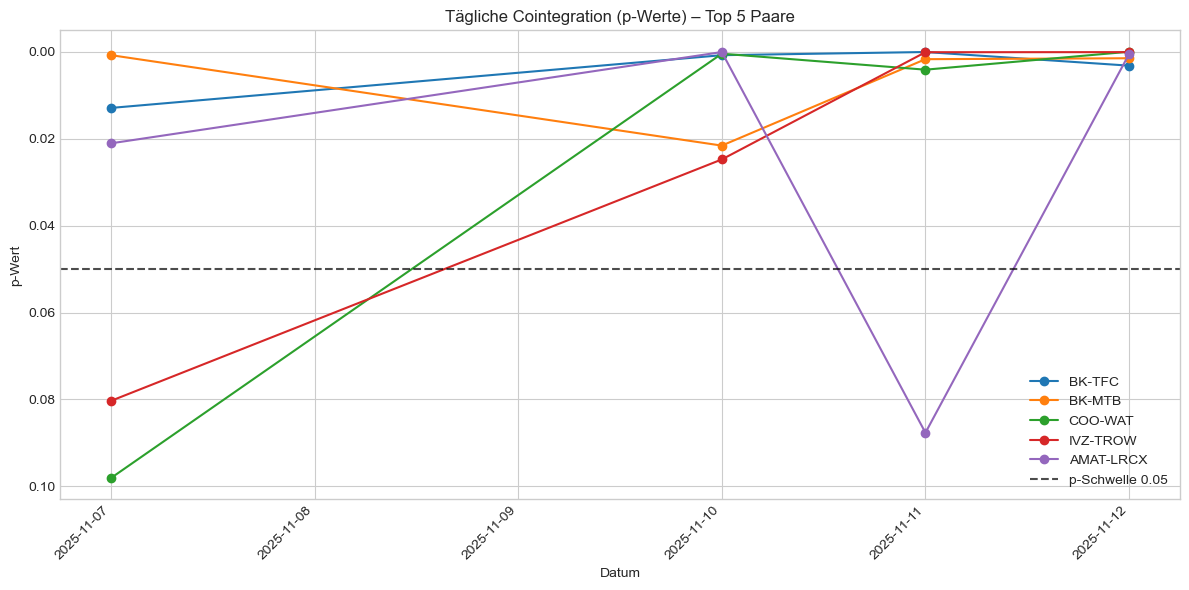

In [ ]:
top_n_plot = 10  # Wie viele Paare im Plot zeigen?

pairs_to_plot = top_pairs_mean_p[["symbol1", "symbol2"]].head(top_n_plot).values

plt.figure(figsize=(12, 6))

for s1, s2 in pairs_to_plot:
    pair_series = (
        daily_coint_df
        .loc[
            (daily_coint_df["symbol1"] == s1) &
            (daily_coint_df["symbol2"] == s2)
        ]
        .sort_values("date")
    )

    label = f"{s1}-{s2}"
    plt.plot(
        pair_series["date"],
        pair_series["pvalue"],
        marker="o",
        linestyle="-",
        label=label
    )

plt.axhline(
    p_thresh,
    linestyle="--",
    alpha=0.7,
    color="black",
    label=f"p-Schwelle {p_thresh}"
)

# y-Achse invertieren → kleine p-Werte oben
plt.gca().invert_yaxis()

plt.title(f"Tägliche Cointegration (p-Werte) – Top {top_n_plot} Paare (beste mean_p)")
plt.xlabel("Datum")
plt.ylabel("p-Wert")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


Als nächstes wird ein **Cointegration-Netzwerk** konstruiert, um die Beziehungen zwischen den stabilsten Paaren visuell darzustellen.

In diesem Netzwerk gilt:

- **Knoten** = Aktien  
- **Kanten** = Paare, die die Cointegrationskriterien erfüllen  
- Jede Kante enthält zusätzliche Attribute wie  
  - `mean_p`
  - `Konsistenz`
  - `n_days`
  - `n_sig_days`

Diese beiden Netzwerke machen sichtbar, welche Assets stark miteinander verbunden sind und hilft, Cluster und potenzielle Handelsgruppen zu identifizieren. Der Unterschied zwischen der Konsistenz in täglicher Cointegration und durchschnittlicher täglicher Cointegration wird auch ersichtlich gemacht. Es ergeben sich nicht die gleichen Strukturen oder Paare.


In [ ]:
def draw_coint_network(edges_df, title):
    """Hilfsfunktion: baut Graph und zeichnet Netzwerk."""
    if edges_df.empty:
        print("edges_df ist leer (keine Paare vorhanden)")
        return

    # --- Graph aufbauen ---
    G = nx.Graph()

    for _, row in edges_df.iterrows():
        s1 = row["symbol1"]
        s2 = row["symbol2"]

        G.add_edge(
            s1,
            s2,
            mean_p=row["mean_p"],
            consistency=row["consistency"],
            n_days=row["n_days"],
            n_sig_days=row["n_sig_days"]
        )

    if G.number_of_edges() == 0:
        print("Keine Kanten im Graphen – evtl. sind die gefilterten Paare leer.")
        return

    plt.figure(figsize=(16, 12))

    n_nodes = G.number_of_nodes()
    k = 4

    pos = nx.spring_layout(
        G,
        k=k,
        iterations=300,
        seed=42
    )

    degrees = dict(G.degree())
    node_sizes = [2500 + degrees[n] * 900 for n in G.nodes()]

    # Nodes
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color="#77bdfb",
        node_size=node_sizes,
        edgecolors="black",
        linewidths=2.0
    )

    # Edges
    nx.draw_networkx_edges(
        G,
        pos,
        width=3.5,
        edge_color="#555555",
        alpha=0.75
    )

    # Node-Labels
    nx.draw_networkx_labels(
        G,
        pos,
        font_size=20,
        font_weight="bold"
    )

    # Kantenlabels: mean_p und Konsistenz
    edge_labels = {
        (u, v): f"{d['mean_p']:.3f} | {d['consistency']:.0%}"
        for u, v, d in G.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=16,
        font_color="darkred",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9)
    )

    plt.title(title, fontsize=26, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


top_n_network = 5

# Netzwerk 1: Top-N nach mean_p
edges_mean_p = top_pairs_mean_p.head(top_n_network).copy()

draw_coint_network(
    edges_mean_p,
    title=f"Cointegration-Netzwerk – Top {top_n_network} Paare (beste mean_p)"
)

# Netzwerk 2: Top-N nach Konsistenz (p < p_thresh)
edges_consistency = top_pairs_consistency.head(top_n_network).copy()

draw_coint_network(
    edges_consistency,
    title=f"Cointegration-Netzwerk – Top {top_n_network} Paare nach Konsistenz (p < {p_thresh})"
)


NameError: name 'edges_df' is not defined

Für intraday-orientierte Pairs-Trading ist es entscheidend, dass ein Paar **häufig** cointegrated ist. Die tägliche Konsistenz ist deshalb der robustere und praxisrelevantere Maßstab als der Durchschnitt der p-Werte.


Zum besseren Verständnis der Cointegration werden die **Top 5 Paare** anhand ihrer Intraday-Preisverläufe betrachtet.  
Als Beispiel dient hierbei der **letzte verfügbare Handelstag** im Datensatz.

Für jedes dieser Paare werden:

- die Intraday-Logpreise wieder in lineare Preise zurückgerechnet,
- beide Preisreihen auf **1 am ersten Zeitpunkt normiert**, um ihre Bewegungen direkt vergleichen zu können,
- die Kennzahlen `mean_p` und `consistency` aus der Cointegrationsanalyse im Titel ergänzt.

Die Plots zeigen somit exemplarisch, wie sich cointegrated Paare **intraday gemeinsam bewegen** und ob ihre Preisrelation stabil bleibt – ein wichtiges Indiz für ein funktionierendes Spread-Modell.


Letzter Tag: 2025-11-13


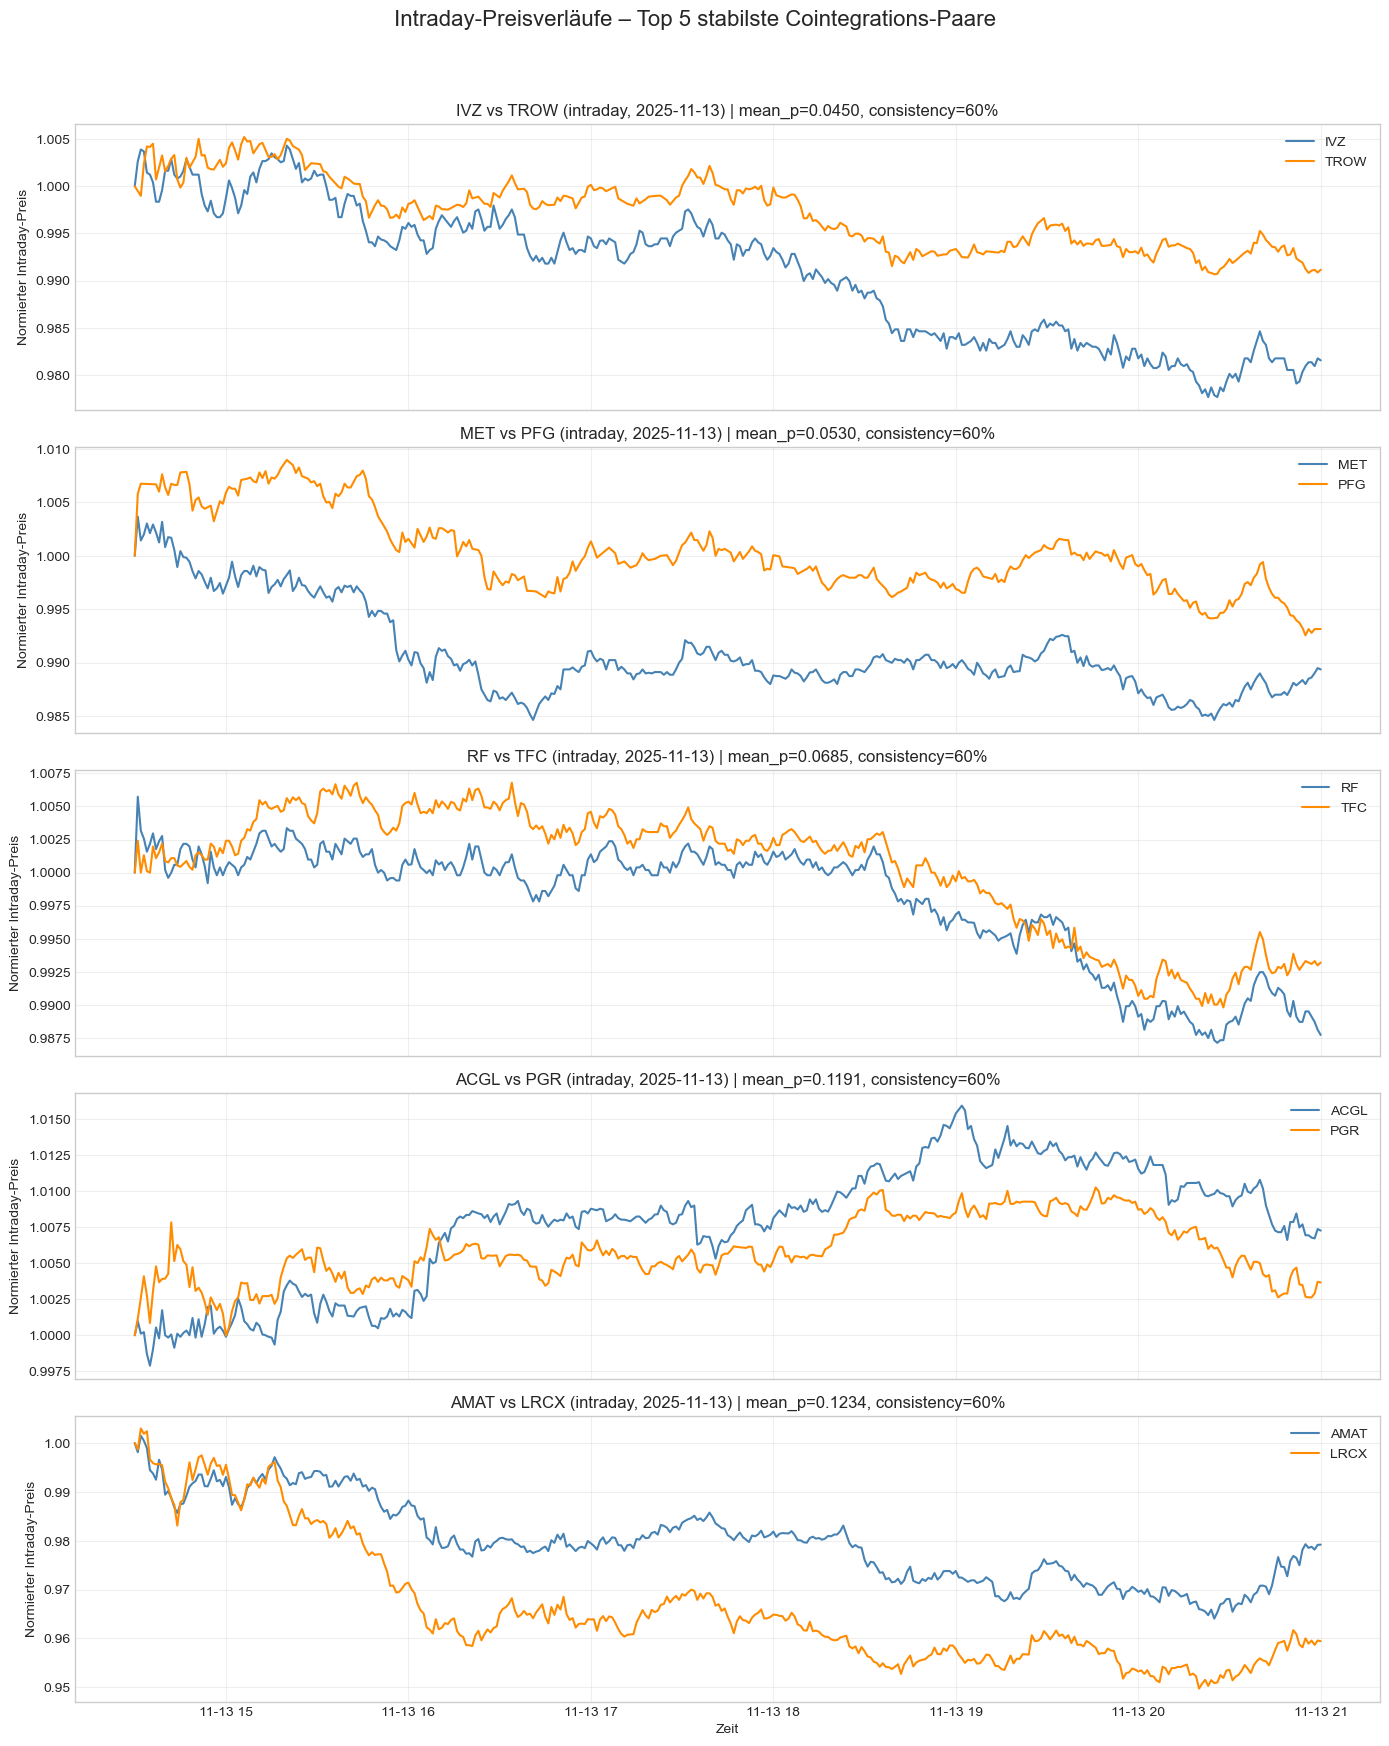

In [ ]:
top_n = 5

if top_pairs.empty:
    raise ValueError("top_pairs ist leer")

# --- letztes Datum bestimmen ---
last_day = log_prices.index.date.max()
print("Letzter Tag:", last_day)

# Rows vom letzten Tag extrahieren
intraday = log_prices[log_prices.index.date == last_day]

if intraday.empty:
    raise ValueError("Keine Intraday-Daten für den letzten Tag gefunden!")

pairs_to_plot = top_pairs.head(top_n)[["symbol1", "symbol2"]].values

fig, axes = plt.subplots(top_n, 1, figsize=(14, 3.5 * top_n), sharex=True)

for idx, (s1, s2) in enumerate(pairs_to_plot):

    # --- Intraday-Daten holen ---
    p1 = intraday[s1].copy()
    p2 = intraday[s2].copy()

    # Falls Lücken vorhanden sind, droppen wir NA
    aligned = pd.concat([p1, p2], axis=1).dropna()
    aligned.columns = [s1, s2]

    # Zurücktransformieren (log → Preis)
    p1_lin = np.exp(aligned[s1])
    p2_lin = np.exp(aligned[s2])

    # Normieren auf 1 am ersten Zeitpunkt
    p1_norm = p1_lin / p1_lin.iloc[0]
    p2_norm = p2_lin / p2_lin.iloc[0]

    # --- Plot ---
    ax = axes[idx]
    ax.plot(p1_norm, label=s1, color="steelblue")
    ax.plot(p2_norm, label=s2, color="darkorange")

    # Mean_p & Consistency anzeigen
    row = top_pairs[(top_pairs["symbol1"] == s1) & (top_pairs["symbol2"] == s2)].iloc[0]

    mean_p = row["mean_p"]
    consistency = row["consistency"]

    ax.set_title(
        f"{s1} vs {s2} (intraday, {last_day}) | mean_p={mean_p:.4f}, consistency={consistency:.0%}",
        fontsize=12
    )
    ax.set_ylabel("Normierter Intraday-Preis")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Zeit")
plt.suptitle("Intraday-Preisverläufe – Top 5 stabilste Cointegrations-Paare", fontsize=16, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


Für die ausgewählten Top-Paare werden nun tägliche Spread-Kennzahlen berechnet.  
Für jeden Tag wird der Spread aus den beiden log-Preisreihen gebildet und anschließend dessen Mittelwert, Standardabweichung sowie Min-/Max-Werte gespeichert.  
Die Ergebnisse werden in `daily_spread_df` gesammelt und zeitlich sortiert.


In [110]:
pairs_to_plot = top_pairs.head(top_n)[["symbol1", "symbol2"]].values
pairs_to_plot

# sicherstellen, dass wir einen DatetimeIndex haben
if not isinstance(log_prices.index, pd.DatetimeIndex):
    raise TypeError("log_prices.index muss ein DatetimeIndex sein.")

# Alle Tage (nur Datum, ohne Zeit)
all_days = log_prices.index.normalize().unique()

daily_spread_records = []

for s1, s2 in pairs_to_plot:
    for day in all_days:
        day_mask = log_prices.index.normalize() == day
        day_prices = log_prices.loc[day_mask, [s1, s2]].dropna()

        if len(day_prices) == 0:
            continue

        spread = day_prices[s1] - day_prices[s2]
        mean_spread = spread.mean()
        std_spread = spread.std()
        min_spread = spread.min()
        max_spread = spread.max()

        daily_spread_records.append({
            "date": day,
            "symbol1": s1,
            "symbol2": s2,
            "mean_spread": mean_spread,
            "std_spread": std_spread,
            "min_spread": min_spread,
            "max_spread": max_spread
        })

daily_spread_df = pd.DataFrame(daily_spread_records)
daily_spread_df = daily_spread_df.sort_values(["symbol1", "symbol2", "date"]).reset_index(drop=True)

display(daily_spread_df.head())


,date,symbol1,symbol2,mean_spread,std_spread,min_spread,max_spread
0,2025-11-07,ACGL,PGR,-0.887082,0.002804,-0.894655,-0.874789
1,2025-11-10,ACGL,PGR,-0.883626,0.002935,-0.888777,-0.876855
2,2025-11-11,ACGL,PGR,-0.885730,0.001791,-0.890216,-0.882302
3,2025-11-12,ACGL,PGR,-0.882853,0.001502,-0.888066,-0.877828
4,2025-11-13,ACGL,PGR,-0.879637,0.002772,-0.889182,-0.874593


Anschließend werden die täglichen Mittelwerte des Spreads für jedes Top-Paar geplottet.  
Jeder Plot zeigt den Verlauf des täglichen Mean-Spreads sowie eine Linie mit dem Gesamtmittelwert über alle Tage.  
So lässt sich der zeitliche Verlauf der Spread-Mittelwerte übersichtlich vergleichen.


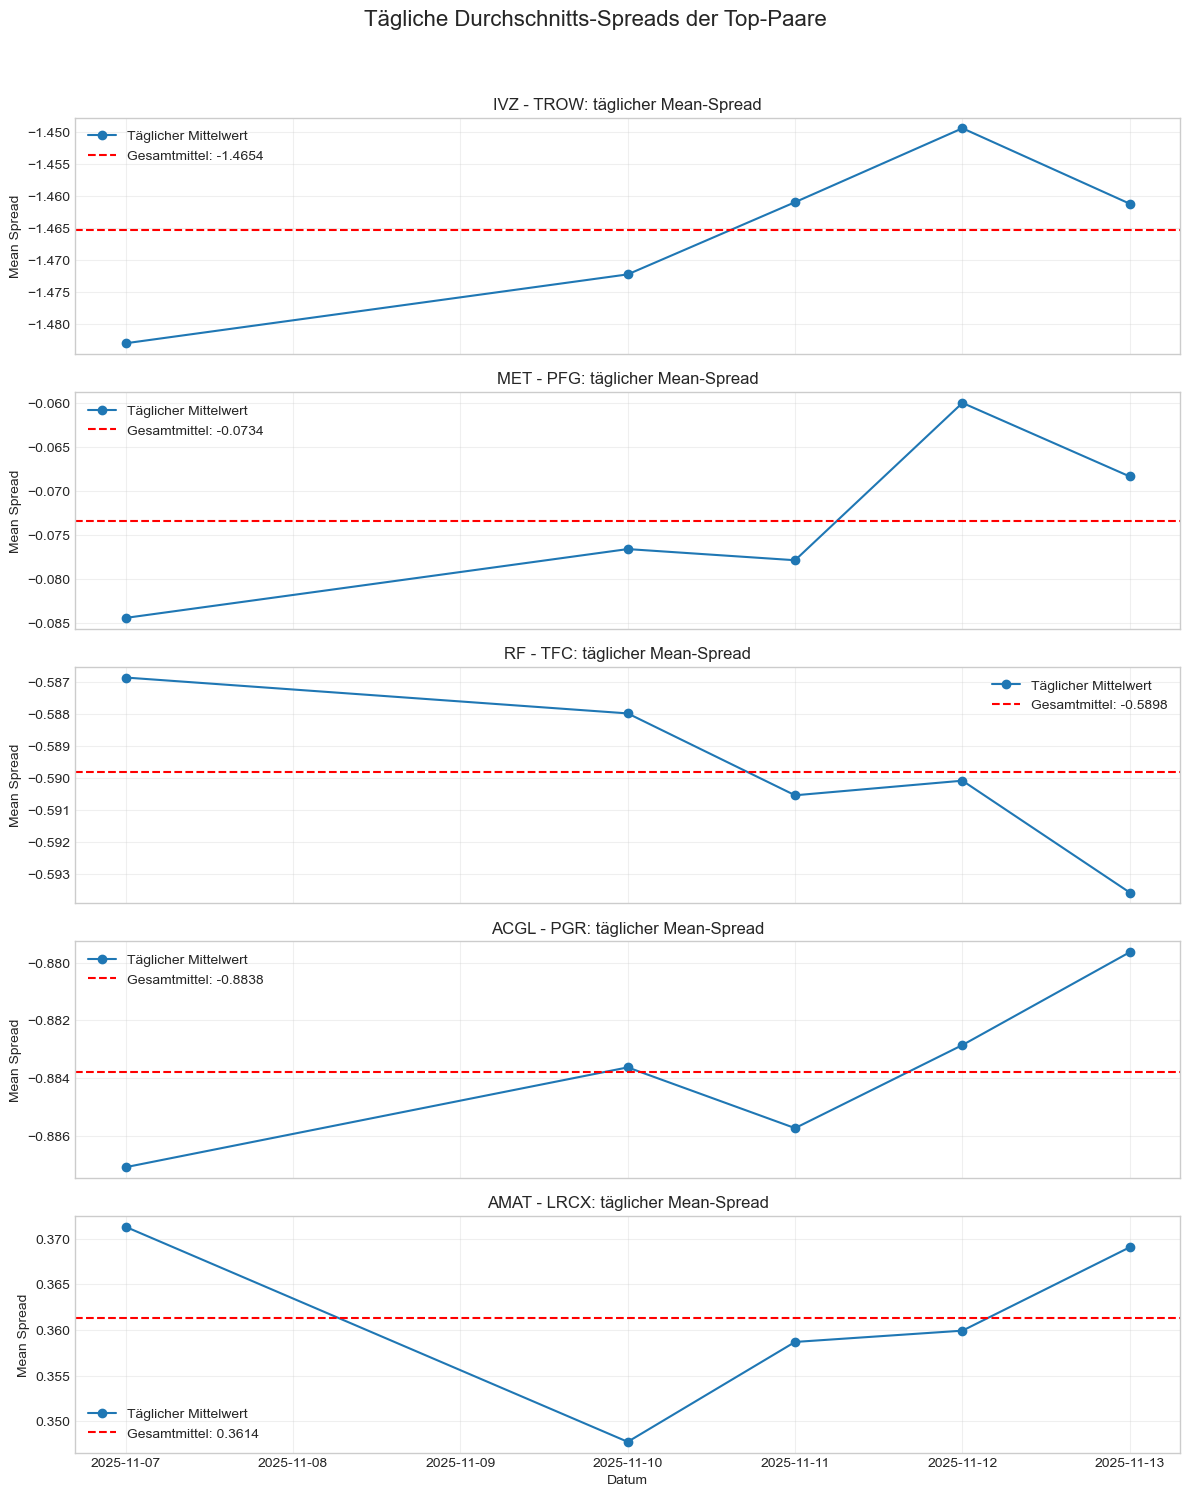

In [ ]:
n_pairs = len(pairs_to_plot)

fig, axes = plt.subplots(n_pairs, 1, figsize=(12, 3.0 * n_pairs), sharex=True)

# Falls nur ein Paar → axes nicht array, sondern einzelnes Axes-Objekt
if n_pairs == 1:
    axes = [axes]

for idx, (s1, s2) in enumerate(pairs_to_plot):
    ax = axes[idx]

    pair_spreads = (
        daily_spread_df
        .loc[
            (daily_spread_df["symbol1"] == s1) &
            (daily_spread_df["symbol2"] == s2)
        ]
        .sort_values("date")
    )

    if pair_spreads.empty:
        ax.set_visible(False)
        continue

    mean_overall = pair_spreads["mean_spread"].mean()

    ax.plot(
        pair_spreads["date"],
        pair_spreads["mean_spread"],
        marker="o",
        linestyle="-",
        label="Täglicher Mittelwert"
    )
    ax.axhline(mean_overall, color="red", linestyle="--",
               label=f"Gesamtmittel: {mean_overall:.4f}")

    ax.set_title(f"{s1} - {s2}: täglicher Mean-Spread")
    ax.set_ylabel("Mean Spread")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Datum")
plt.suptitle("Tägliche Durchschnitts-Spreads der Top-Paare", fontsize=16, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


Zum Schluss wird der Spread der Top-Paare intraday am letzten verfügbaren Tag dargestellt.  
Für jedes Paar wird der Intraday-Spread geplottet und mit dem Tagesmittelwert ergänzt.  
Die Visualisierung zeigt den Spread-Verlauf innerhalb des Tages als Beispielansicht.


Letzter Tag: 2025-11-13


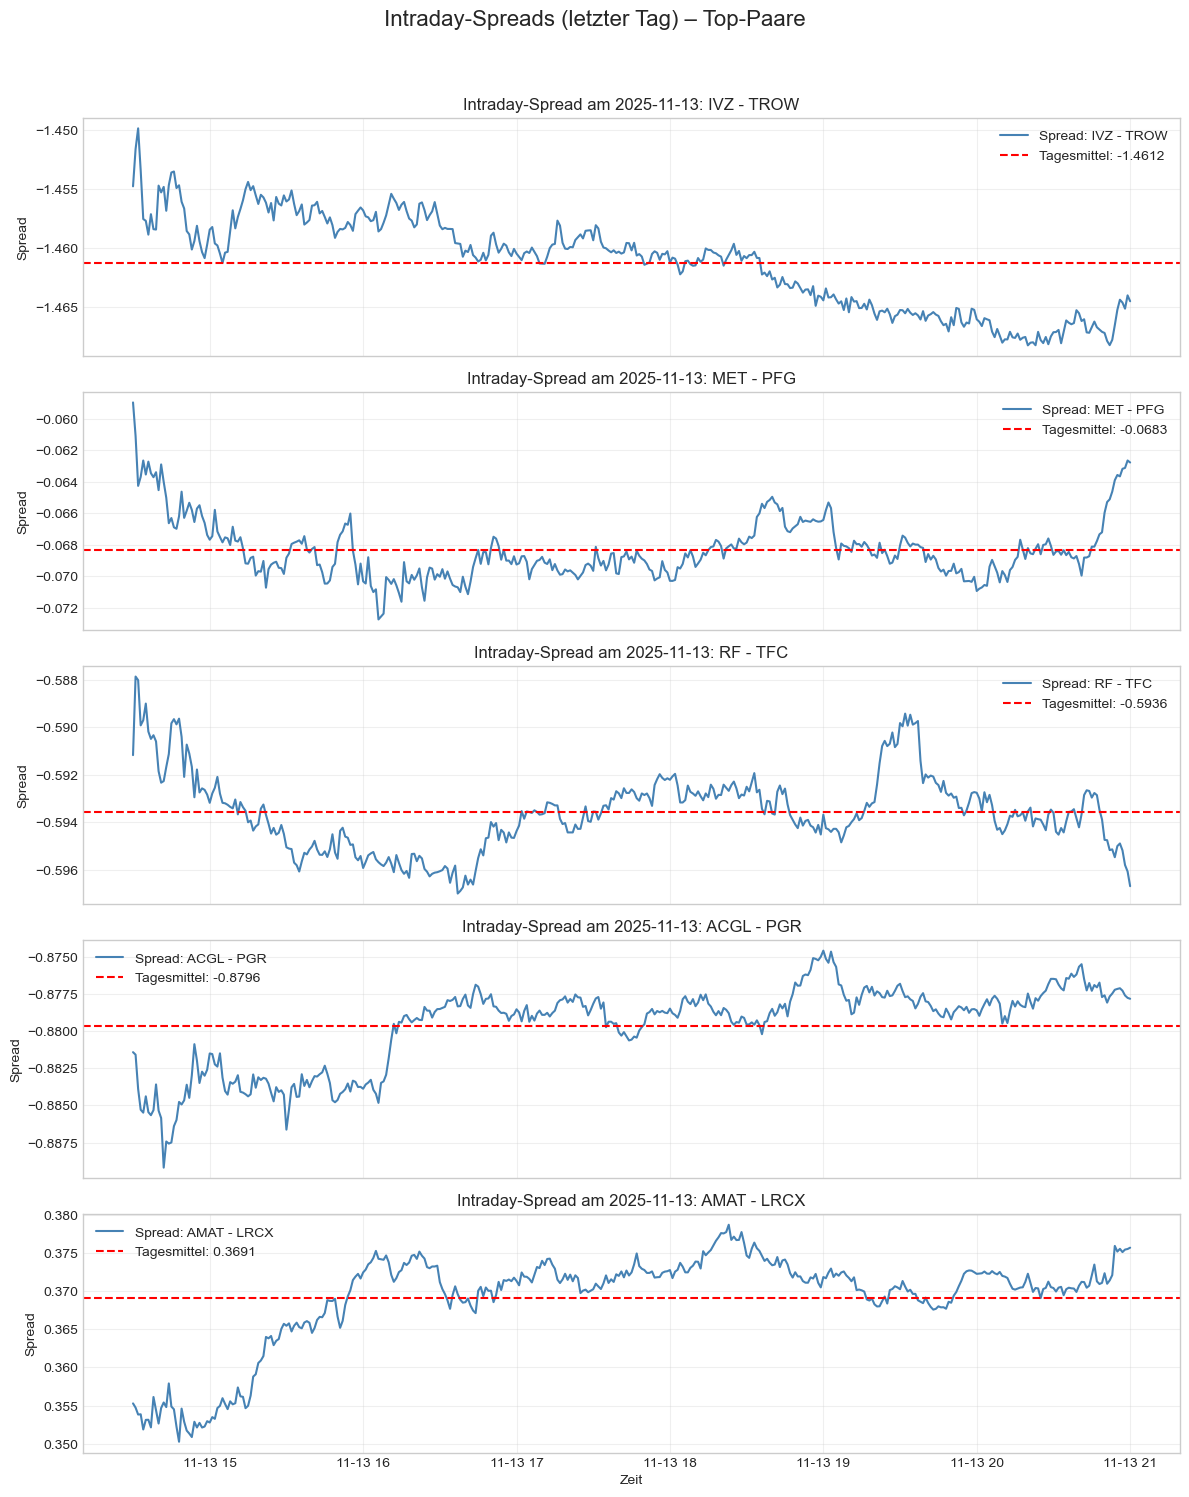

In [ ]:
# letzten Tag bestimmen
last_day = log_prices.index.normalize().max()
print("Letzter Tag:", last_day.date())

intraday_last = log_prices[log_prices.index.normalize() == last_day]

if intraday_last.empty:
    raise ValueError("Keine Daten für den letzten Tag gefunden.")

n_pairs = len(pairs_to_plot)
fig, axes = plt.subplots(n_pairs, 1, figsize=(12, 3.0 * n_pairs), sharex=True)

if n_pairs == 1:
    axes = [axes]

for idx, (s1, s2) in enumerate(pairs_to_plot):
    ax = axes[idx]

    intraday_pair = intraday_last[[s1, s2]].dropna()

    if intraday_pair.empty:
        ax.set_visible(False)
        continue

    spread = intraday_pair[s1] - intraday_pair[s2]
    mean_spread = spread.mean()

    ax.plot(
        spread.index,
        spread,
        label=f"Spread: {s1} - {s2}",
        color="steelblue"
    )
    ax.axhline(
        mean_spread,
        color="red",
        linestyle="--",
        label=f"Tagesmittel: {mean_spread:.4f}"
    )

    ax.set_title(f"Intraday-Spread am {last_day.date()}: {s1} - {s2}")
    ax.set_ylabel("Spread")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Zeit")
plt.suptitle("Intraday-Spreads (letzter Tag) – Top-Paare", fontsize=16, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 3.3.3. Technischen Indikatoren
Feedback von Herr WWürsch (siehe Mail):
Versuchen Sie, mittels klassischer Aktien-Indikatoren zu prüfen, ob diese auch die gleichen Cluster ergeben

### 3.3.4. Fazit
Hier kommt die Erklärung, warum die Cluster der Cointegration so sind und warum die Cluster der technischen Indikatoren so sind. Lässt sich das cross-validieren? --> Heatmap

Zum Schluss sollten die Daten der gewählten Paare in eine CSV-Datei geschreiben werden, damit es sauber gespeichert wird und im nächsten Dokument einfach eingelesen werden kann.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="02_Datensammlung.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="04_.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
